# 07 — Error Analysis

All models, TIDE breakdown, confusion matrices, failure galleries, report tables.

In [1]:
import os, sys
from pathlib import Path

if Path.cwd().name == "notebooks":          # always run from the repository root
    os.chdir(Path.cwd().parent)
sys.path.insert(0, str(Path("src").resolve()))  # use the local `vdet` package even without `pip install -e .`

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from vdet.paths import P
from vdet.notebook import *   # setup_notebook, results_table, show_image, *_experiment, evaluate_preds, ...

setup_notebook(seed=42)

# Training cells are resumable: a run whose checkpoint already exists in checkpoints/ is not
# trained again (its training log and metrics are loaded). Delete the checkpoint to retrain.

REGENERATE_FIGURES = False

Project root : /home/marko/ucu-ai-hw-2
Data         : /home/marko/ucu-ai-hw-2/data (exists=True)
Cache        : /home/marko/ucu-ai-hw-2/cache (exists=True)
Checkpoints  : /home/marko/ucu-ai-hw-2/checkpoints
Device       : NVIDIA GeForce RTX 4050 Laptop GPU


## 1. All models at a glance

,run_id,family,exp,imgsz,epochs_done,gpu_h,AP,AP50,AP75,APs,APm,APl,AR500,fps
16,pipeline-night-boost,pipeline,final,1280,0,0.0000,0.3129,0.5891,0.2885,0.1751,0.2747,0.6737,0.5335,NaN
17,temporal-rescore-boost,pipeline,rescore,1280,0,0.0000,0.3114,0.5879,0.2866,0.1743,0.2732,0.6712,0.5308,NaN
22,pipeline-night-boost-causal,temporal,causal,1280,0,0.0000,0.3104,0.5856,0.2861,0.1717,0.2727,0.6714,0.5326,NaN
15,ensemble-wbf-boost,pipeline,wbf,1280,0,0.0000,0.3046,0.5744,0.2807,0.1679,0.2675,0.6712,0.5308,NaN
9,pipeline-final,pipeline,final,1280,0,0.0000,0.2996,0.5638,0.2786,0.1574,0.2611,0.6736,0.5287,NaN
14,temporal-rescore,pipeline,rescore,1280,0,0.0000,0.2979,0.5620,0.2763,0.1559,0.2596,0.6710,0.5263,NaN
21,pipeline-final-causal,temporal,causal,1280,0,0.0000,0.2966,0.5594,0.2755,0.1528,0.2592,0.6715,0.5275,NaN
8,ensemble-wbf,pipeline,wbf,1280,0,0.0000,0.2902,0.5469,0.2695,0.1490,0.2526,0.6710,0.5263,NaN
10,rtdetr-e0,rtdetr,e0,1280,3,1.5184,0.2654,0.5129,0.2400,0.1370,0.2378,0.6077,0.4329,9.04
11,rtdetr-e1,rtdetr,e1,1280,2,1.5306,0.2606,0.5012,0.2393,0.1307,0.2341,0.6307,0.5006,8.82


[timer] Summary figures (size_breakdown, map_vs_fps, per_class_ap, curves): 1.60s


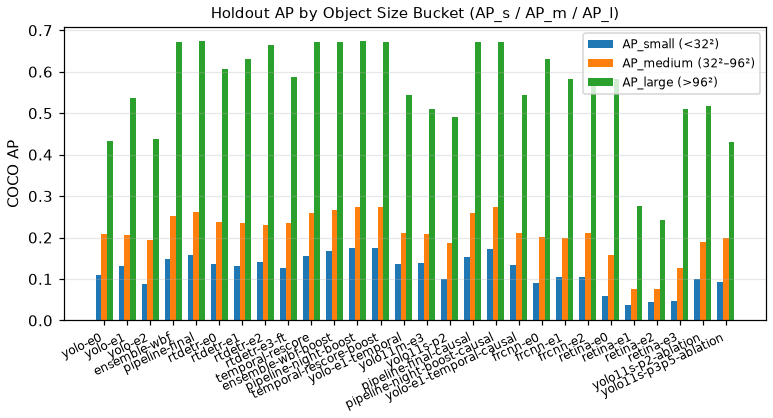

[timer] Summary figures (size_breakdown, map_vs_fps, per_class_ap, curves): 1.54s


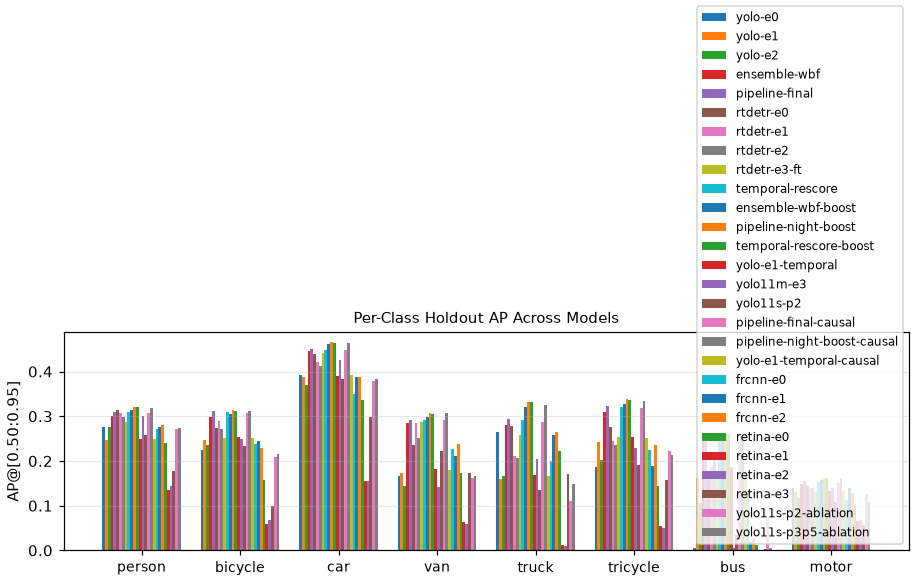

[timer] Summary figures (size_breakdown, map_vs_fps, per_class_ap, curves): 1.48s


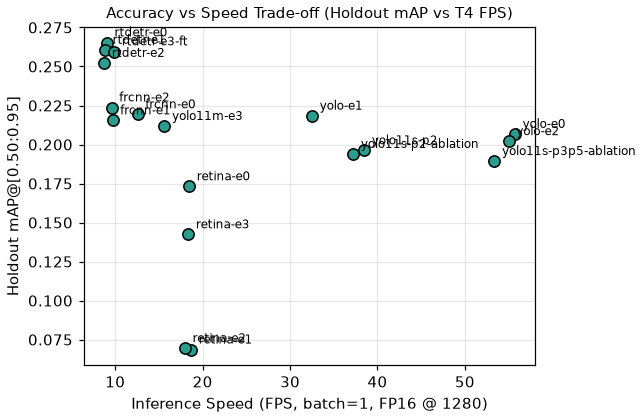

[timer] Summary figures (size_breakdown, map_vs_fps, per_class_ap, curves): 1.48s


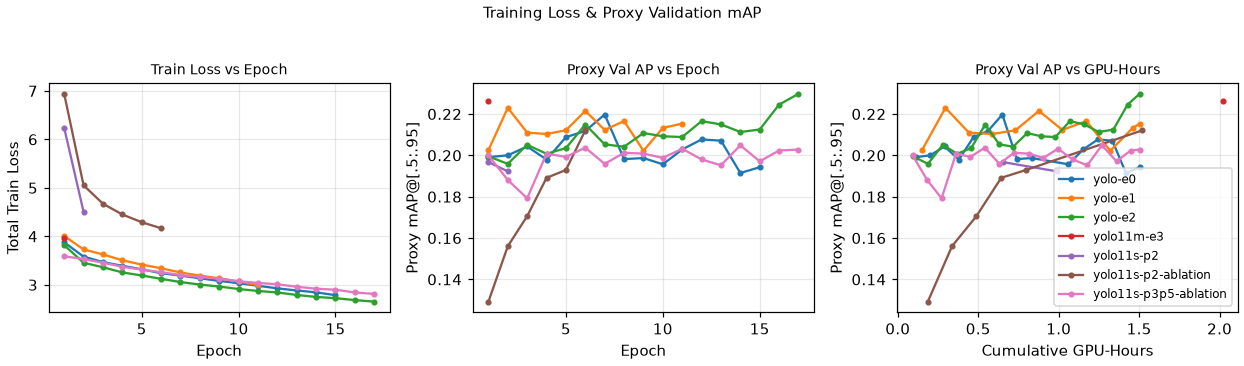

[timer] Summary figures (size_breakdown, map_vs_fps, per_class_ap, curves): 1.47s


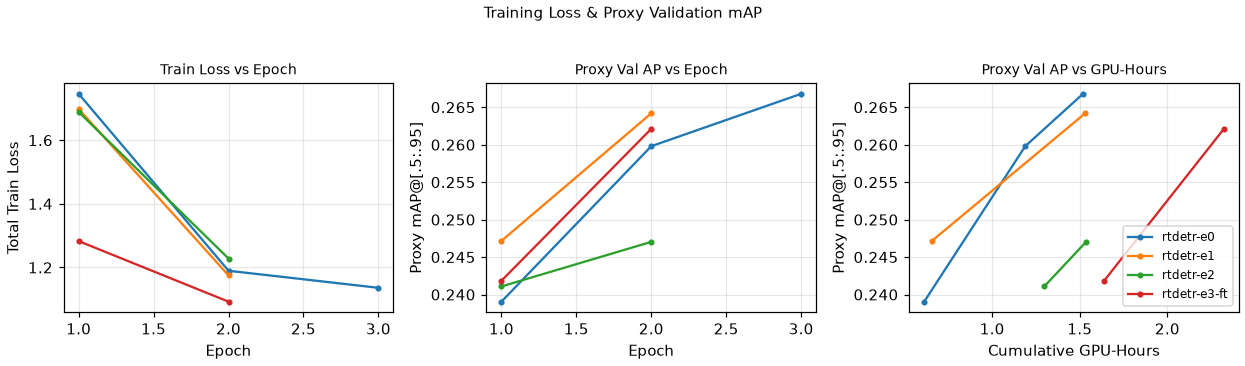

[timer] Summary figures (size_breakdown, map_vs_fps, per_class_ap, curves): 1.37s


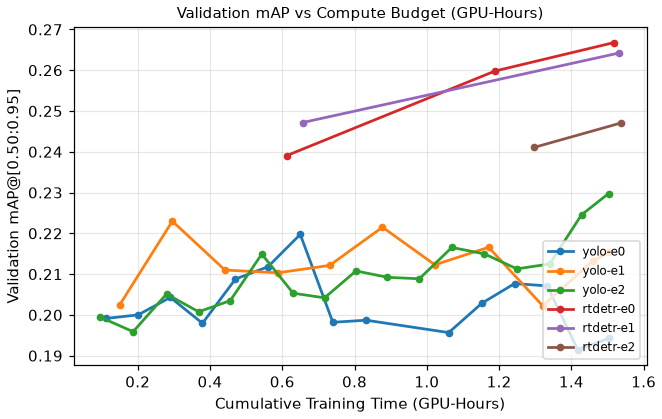

In [2]:
from vdet import diagnostics as diag

_, eval_df = diag.load_results()
display(eval_df[[c for c in DEFAULT_COLS if c in eval_df.columns]].sort_values("AP", ascending=False).round(4))

for name in ["size_breakdown.png", "per_class_ap.png", "map_vs_fps.png", "curves_yolo.png", "curves_rtdetr.png", "map_vs_gpu_time_all.png"]:
    figure_or_generate(name, diag.make_summary_figures, regenerate=REGENERATE_FIGURES, width=800)

## 2. Error breakdown (TIDE; confidence ≥ 0.20, top-100 per frame)

[timer] TIDE & failure gallery (yolo: yolo-e1): 8.97s


[timer] TIDE & failure gallery (rtdetr: rtdetr-e0): 9.29s


[timer] TIDE & failure gallery (faster_rcnn: frcnn-e2): 9.00s


[timer] TIDE & failure gallery (retinanet: retina-e2): 8.95s


[timer] TIDE & failure gallery (pipeline: pipeline-final): 9.06s


,TP,Cls,Loc,Both,Dupe,Bkg,Miss,Miss_small,Miss_medium,Miss_large
yolo-e1,61530,9575,4850,1993,587,11808,52602,13401,36432,2769
rtdetr-e0,82323,22428,13689,9120,5489,52036,31809,9771,20819,1219
frcnn-e2,71010,13273,11731,6948,5295,18858,43122,11930,29259,1933
retina-e2,54311,22260,28767,10668,12306,22108,59821,13588,38846,7387
pipeline-final,81262,20515,9323,5696,682,30505,32870,10287,21337,1246


,Cls,Loc,Both,Dupe,Bkg,Miss
yolo-e1,11.8,6.0,2.4,0.7,14.5,64.6
rtdetr-e0,16.7,10.2,6.8,4.1,38.7,23.6
frcnn-e2,13.4,11.8,7.0,5.3,19.0,43.5
retina-e2,14.3,18.4,6.8,7.9,14.2,38.4
pipeline-final,20.6,9.4,5.7,0.7,30.6,33.0


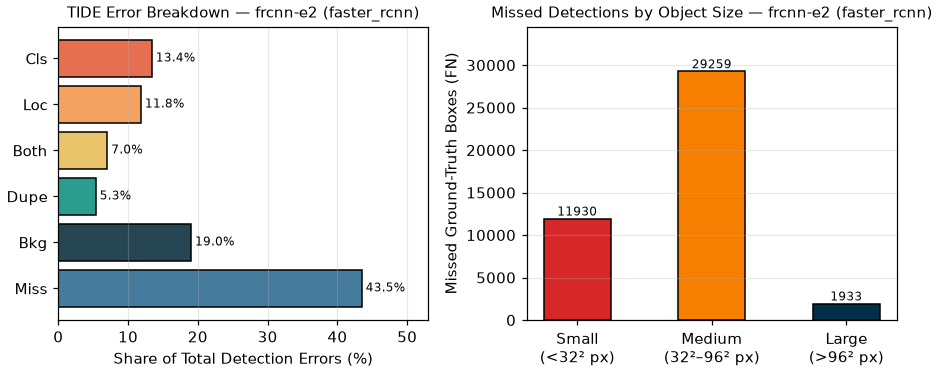

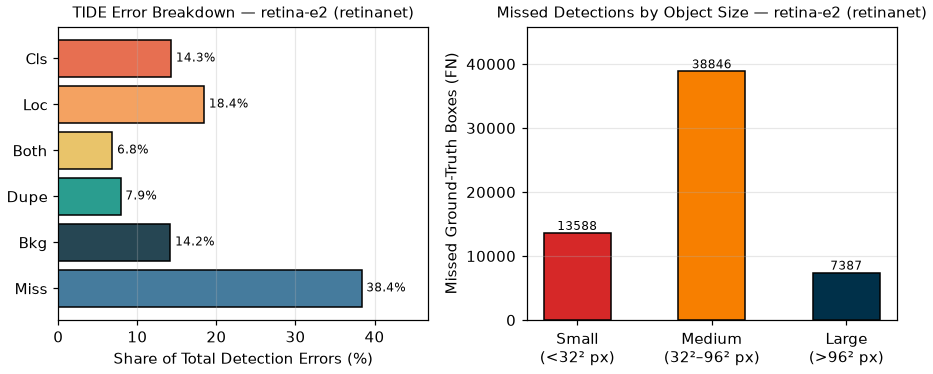

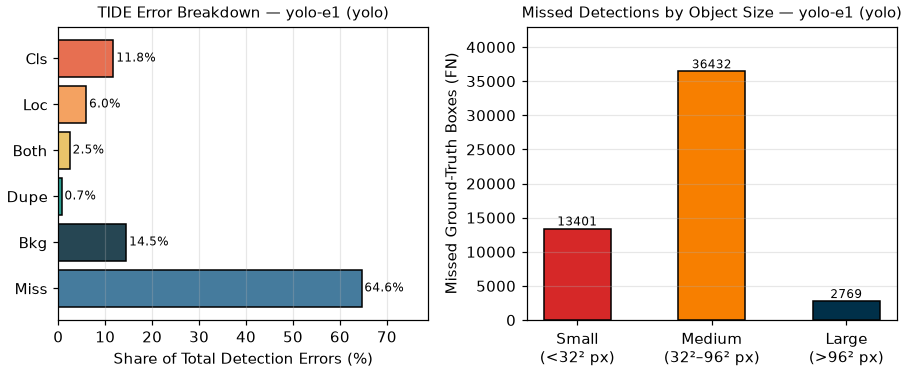

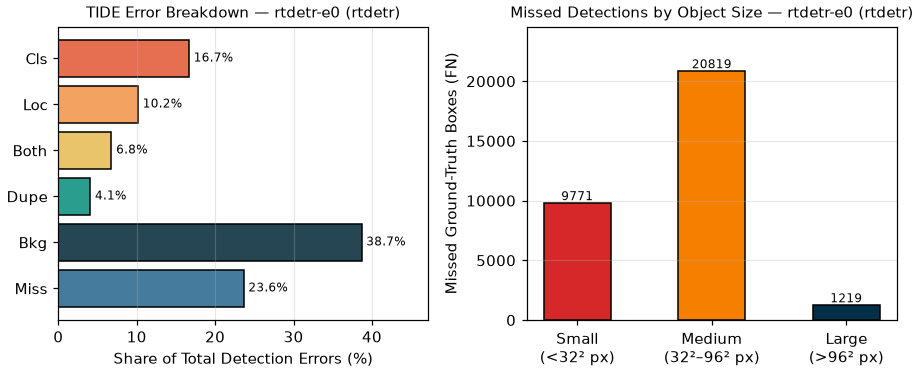

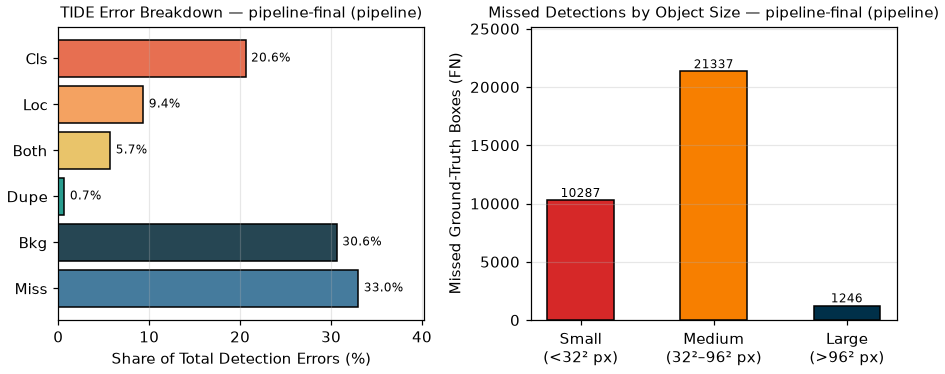

In [3]:
from vdet.utils import load_json
tide_path = P.experiments / "tide_breakdown_summary.json"
if REGENERATE_FIGURES or not tide_path.exists():
    diag.make_tide_and_failure_figures()
tide = load_json(tide_path)
display(pd.DataFrame({rid: t["counts"] for rid, t in tide.items()}).T)
display(pd.DataFrame({rid: t["shares_pct"] for rid, t in tide.items()}).T.round(1))
for fam in ["faster_rcnn", "retinanet", "yolo", "rtdetr", "pipeline"]:
    show_image(f"tide_{fam}.png", 750)

### Failure galleries (ground truth vs predictions)

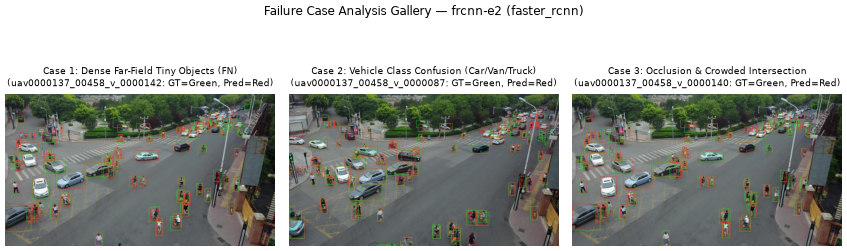

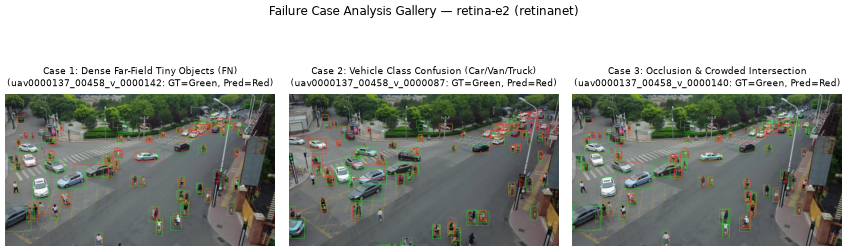

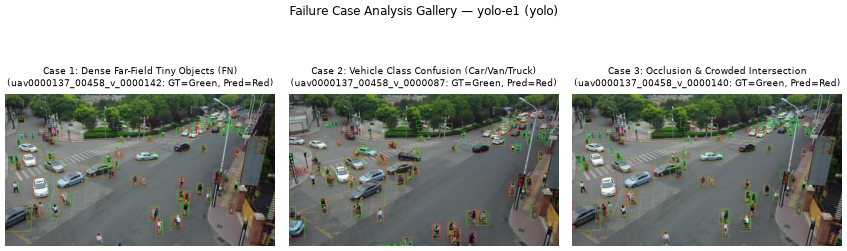

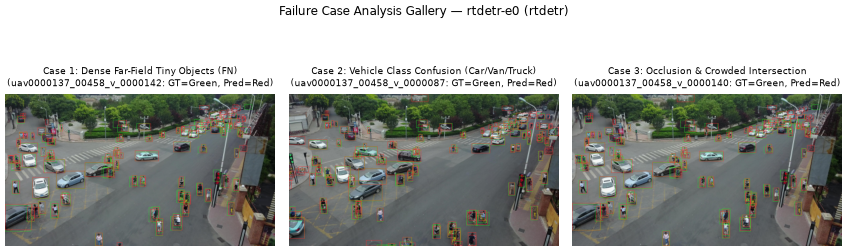

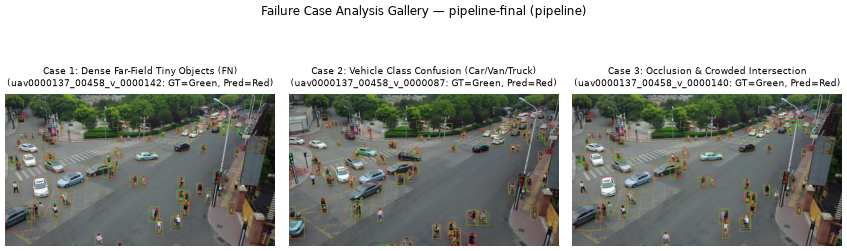

In [4]:
for fam in ["faster_rcnn", "retinanet", "yolo", "rtdetr", "pipeline"]:
    show_image(f"failures_{fam}.png", 900)

**Notes.** Misses dominate for single models; the pipeline turns misses into TPs but adds background FPs. Largest confusions: `van → car`, `bicycle ↔ motor`, `motor → person`.

In [5]:
from vdet.constants import CLASS_NAMES
for rid, t in tide.items():
    cm = pd.DataFrame(t["confusion_matrix"], index=CLASS_NAMES, columns=CLASS_NAMES)
    print(f"{rid}: confusion matrix (rows = ground-truth class, columns = predicted class)")
    display(cm)

yolo-e1: confusion matrix (rows = ground-truth class, columns = predicted class)


,person,bicycle,car,van,truck,tricycle,bus,motor
person,27926,97,1,0,0,6,0,554
bicycle,120,2740,6,0,0,60,0,1471
car,0,0,19990,223,104,260,3,3
van,0,0,2970,2249,145,57,5,0
truck,0,0,32,106,611,96,0,0
tricycle,100,72,227,45,321,2467,0,520
bus,0,0,145,154,7,1,47,0
motor,966,534,4,0,0,160,0,5500


rtdetr-e0: confusion matrix (rows = ground-truth class, columns = predicted class)


,person,bicycle,car,van,truck,tricycle,bus,motor
person,38509,657,2,0,1,2,0,1107
bicycle,317,3798,12,0,0,114,0,1400
car,0,0,24628,2058,321,202,33,3
van,0,3,4343,3650,321,133,204,1
truck,0,0,329,371,881,151,85,0
tricycle,437,430,981,460,762,3498,92,1184
bus,0,0,253,182,5,9,75,0
motor,2683,2588,13,6,1,172,0,7284


frcnn-e2: confusion matrix (rows = ground-truth class, columns = predicted class)


,person,bicycle,car,van,truck,tricycle,bus,motor
person,35513,58,11,0,0,3,0,419
bicycle,296,2725,2,1,0,61,0,1462
car,5,0,20728,1058,231,104,13,2
van,1,0,3426,2982,251,3,57,0
truck,0,0,141,72,801,49,0,0
tricycle,408,137,425,249,205,2120,4,527
bus,0,0,197,17,68,0,19,0
motor,2800,331,64,0,0,115,0,6122


retina-e2: confusion matrix (rows = ground-truth class, columns = predicted class)


,person,bicycle,car,van,truck,tricycle,bus,motor
person,28670,1148,12,0,0,124,0,1616
bicycle,822,1935,9,0,0,102,0,1314
car,23,0,15749,1739,228,428,51,197
van,0,0,4244,1323,534,307,87,34
truck,0,0,282,61,200,152,15,1
tricycle,619,183,685,305,134,1438,1,810
bus,0,0,103,6,3,0,0,0
motor,3477,1366,251,6,0,781,0,4996


pipeline-final: confusion matrix (rows = ground-truth class, columns = predicted class)


,person,bicycle,car,van,truck,tricycle,bus,motor
person,36652,345,0,0,0,0,0,1083
bicycle,230,3856,3,0,0,155,0,2414
car,0,0,24557,1602,418,449,18,15
van,0,1,4636,3834,390,148,104,1
truck,0,0,201,216,917,169,43,0
tricycle,285,196,616,234,860,3801,23,1319
bus,0,0,246,200,50,22,82,0
motor,2008,1634,4,3,0,174,0,7563


## 3. Report tables

In [6]:
md_table = diag.write_report_tables()
print(md_table)

Saved report-ready Markdown summary table to /home/marko/ucu-ai-hw-2/experiments/report_tables.md
# Master Experimental Results Table (Auto-Generated from `experiments/results.csv`)

| run_id | family | exp | imgsz | epochs_done | gpu_h | AP | AP50 | AP75 | APs | APm | APl | AR500 | fps |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| yolo-e0 | yolo | e0 | 1280 | 15 | 1.50 | 0.2067 | 0.4156 | 0.1785 | 0.1085 | 0.2080 | 0.4339 | 0.3291 | 55.73 |
| yolo-e1 | yolo | e1 | 1600 | 11 | 1.50 | 0.2184 | 0.4346 | 0.1903 | 0.1312 | 0.2068 | 0.5358 | 0.3716 | 32.52 |
| yolo-e2 | yolo | e2 | 1280 | 17 | 1.50 | 0.2021 | 0.3959 | 0.1812 | 0.0872 | 0.1952 | 0.4388 | 0.3081 | 55.01 |
| ensemble-wbf | pipeline | wbf | 1280 | 0 | 0.00 | 0.2902 | 0.5469 | 0.2695 | 0.1490 | 0.2526 | 0.6710 | 0.5263 | - |
| pipeline-final | pipeline | final | 1280 | 0 | 0.00 | 0.2996 | 0.5638 | 0.2786 | 0.1574 | 0.2611 | 0.6736 | 0.5287 | - |
| rtdetr-e0 | rtdetr | e0 | 1280 | 3 | 1